# Import Libraries

In [1]:
# For file and system operations
import urllib.request
import os

# For data download
import yfinance as yf

# For time series analysis
import pandas as pd
import numpy as np
import datetime as dt
import re
import matplotlib.pyplot as plt
import mplfinance as mpf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.linear_model import LinearRegression

# for time series forecasting
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

## For time series forecasting with LSTM
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from tensorflow.keras.optimizers import Adam

# For suppressing warnings
import warnings
warnings.filterwarnings('ignore')

# Ensures that matplotlib plots are displayed directly within the notebook,
# right below the code cell that produces them. It makes visualizations appear
# inline for easier viewing and analysis.
%matplotlib inline

# Load Dataset

In [2]:
start = "2024-01-01"
end = dt.datetime.now().strftime("%Y-%m-%d")

data = yf.download("AMD", start=start, end=end)
data.columns = [col[0] for col in data.columns]  # Flatten MultiIndex to single names

[*********************100%***********************]  1 of 1 completed


# Confirm the Loaded Data

In [3]:
print("\n*1* The number of observations and variables")
display(data.shape)

print("\n*2* The data types:")
display(data.info())


*1* The number of observations and variables


(461, 5)


*2* The data types:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 461 entries, 2024-01-02 to 2025-10-31
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   461 non-null    float64
 1   High    461 non-null    float64
 2   Low     461 non-null    float64
 3   Open    461 non-null    float64
 4   Volume  461 non-null    int64  
dtypes: float64(4), int64(1)
memory usage: 21.6 KB


None

In [4]:
print("\n*3* The summary of the numeric columns:")
display(data.describe())

print("\n*4* The whole dataset:")
display(data)

print("\n*5* The first 5 rows in the dataset:")
display(data.head())

print("\n*6* The last 5 rows in the dataset:")
display(data.tail())


*3* The summary of the numeric columns:


,Close,High,Low,Open,Volume
count,461.000000,461.000000,461.000000,461.000000,4.610000e+02
mean,149.042169,151.909609,146.215879,149.203232,5.162301e+07
std,32.475349,33.194350,31.649106,32.561979,2.510212e+07
min,78.209999,86.139999,76.480003,79.220001,1.608570e+07
25%,125.019997,126.339996,121.910004,124.440002,3.409100e+07
50%,152.309998,155.330002,150.399994,153.009995,4.450770e+07
75%,166.470001,169.630005,163.139999,166.809998,6.185710e+07
max,264.329987,267.079987,257.399994,264.190002,2.488596e+08



*4* The whole dataset:


,Close,High,Low,Open,Volume
Date,,,,,
2024-01-02,138.580002,144.399994,137.429993,144.279999,64902000
2024-01-03,135.320007,137.429993,133.740005,135.710007,61988600
2024-01-04,136.009995,137.699997,134.000000,134.300003,58610300
2024-01-05,138.580002,141.009995,136.440002,136.779999,69657700
2024-01-08,146.179993,147.149994,140.149994,140.360001,71756900
...,...,...,...,...,...
2025-10-27,259.670013,260.420013,249.800003,257.880005,65613100
2025-10-28,258.010010,264.579987,257.000000,259.140015,47448700
2025-10-29,264.329987,267.079987,257.399994,264.190002,49335600



*5* The first 5 rows in the dataset:


,Close,High,Low,Open,Volume
Date,,,,,
2024-01-02,138.580002,144.399994,137.429993,144.279999,64902000
2024-01-03,135.320007,137.429993,133.740005,135.710007,61988600
2024-01-04,136.009995,137.699997,134.000000,134.300003,58610300
2024-01-05,138.580002,141.009995,136.440002,136.779999,69657700
2024-01-08,146.179993,147.149994,140.149994,140.360001,71756900



*6* The last 5 rows in the dataset:


,Close,High,Low,Open,Volume
Date,,,,,
2025-10-27,259.670013,260.420013,249.800003,257.880005,65613100
2025-10-28,258.010010,264.579987,257.000000,259.140015,47448700
2025-10-29,264.329987,267.079987,257.399994,264.190002,49335600
2025-10-30,254.839996,263.880005,252.309998,259.920013,45162500
2025-10-31,256.119995,262.130005,253.410004,259.600006,34404500


# Save the Original Data

In [5]:
# Save the results as a CSV file for further analysis and reporting
output_path = './data/lab_stockprice_original.csv'
# Ensure the data directory exists
if not os.path.exists('./data'):
    os.makedirs('./data')
# Save the CSV file regardless of environment (Google Colab or local)
data.to_csv(output_path, index=True)
print(f"\n✅ Results saved to {output_path}")


✅ Results saved to ./data/lab_stockprice_original.csv


# Data  Cleaning and Preparation

In [6]:
# 1) Ensure datetime index and sorted

# This line converts the `Date` column in the `data` DataFrame to datetime
# objects. The `errors="coerce"` argument means that any value that cannot
# be parsed as a date will be replaced with `NaT` (Not a Time), which is
# pandas' way of marking missing or invalid dates. This helps prevent errors
# from invalid date formats and ensures the column is consistently typed.
if "Date" in data.columns:
    data["Date"] = pd.to_datetime(data["Date"], errors="coerce")
    data = data.set_index("Date")

data = data.sort_index()

# 2) Normalize column names (trim, unify, and fix common naming)
data.columns = [c.strip() for c in data.columns]
rename_map = {
    "Close/Last": "Close",
    "Adj Close": "Close",
    "Adj. Close": "Close",
    "Closing Price": "Close",
    "Open Price": "Open",
    "Opening Price": "Open",
    "High Price": "High",
    "Low Price": "Low",
    "Trade Volume": "Volume",
    "Volume (Shares)": "Volume",
    "Total Volume": "Volume",
    "High/Low": "High",
    "Low/High": "Low"
}
data = data.rename(columns=rename_map)

# 3) Define a helper to strip non-numeric characters (keep digits, dot, minus)
def to_numeric_str(s: str) -> str:
    # Handle None/NaN safely
    s = "" if s is None else str(s)
    # Strip any characters except digits, decimal point, minus
    return re.sub(r"[^0-9.\-]", "", s)

# 4) Coerce OHLC to float
ohlc_cols = [c for c in ["Open", "High", "Low", "Close"] if c in data.columns]
for c in ohlc_cols:
    data[c] = pd.to_numeric(data[c].astype(str).map(to_numeric_str), errors="coerce")

# 5) Coerce Volume to numeric (basic version: strip non-numeric)
if "Volume" in data.columns:
    data["Volume"] = pd.to_numeric(data["Volume"].astype(str).map(to_numeric_str), errors="coerce")

# Optional: if your Volume has K/M/B suffixes (e.g., 12K, 3.5M, 1.2B) and you want correct scaling:
def parse_volume(v):
    v = str(v).strip()
    if not v or v.lower() == "nan":
        return float("nan")
    mult = 1
    if v[-1] in "KkMmBb":
        suffix = v[-1].upper()
        v = to_numeric_str(v[:-1])
        mult = {"K": 1_000, "M": 1_000_000, "B": 1_000_000_000}[suffix]
    else:
        v = to_numeric_str(v)
    return float(v) * mult if v else float("nan")
if "Volume" in data.columns:
    data["Volume"] = data["Volume"].map(parse_volume)

# 6) Drop rows where any of OHLC are missing (mplfinance needs valid OHLC rows)
if ohlc_cols:
    data = data.dropna(subset=ohlc_cols)

# Confirm Cleaned Data

In [7]:
print("\n*1* The number of observations and variables")
display(data.shape)

print("\n*2* The data types:")
display(data.info())


*1* The number of observations and variables


(461, 5)


*2* The data types:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 461 entries, 2024-01-02 to 2025-10-31
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   461 non-null    float64
 1   High    461 non-null    float64
 2   Low     461 non-null    float64
 3   Open    461 non-null    float64
 4   Volume  461 non-null    float64
dtypes: float64(5)
memory usage: 21.6 KB


None

In [8]:
print("\n*3* The summary of the numeric columns:")
display(data.describe())

print("\n*4* The whole dataset:")
display(data)

print("\n*5* The first 5 rows in the dataset:")
display(data.head())

print("\n*6* The last 5 rows in the dataset:")
display(data.tail())


*3* The summary of the numeric columns:


,Close,High,Low,Open,Volume
count,461.000000,461.000000,461.000000,461.000000,4.610000e+02
mean,149.042169,151.909609,146.215879,149.203232,5.162301e+07
std,32.475349,33.194350,31.649106,32.561979,2.510212e+07
min,78.209999,86.139999,76.480003,79.220001,1.608570e+07
25%,125.019997,126.339996,121.910004,124.440002,3.409100e+07
50%,152.309998,155.330002,150.399994,153.009995,4.450770e+07
75%,166.470001,169.630005,163.139999,166.809998,6.185710e+07
max,264.329987,267.079987,257.399994,264.190002,2.488596e+08



*4* The whole dataset:


,Close,High,Low,Open,Volume
Date,,,,,
2024-01-02,138.580002,144.399994,137.429993,144.279999,64902000.0
2024-01-03,135.320007,137.429993,133.740005,135.710007,61988600.0
2024-01-04,136.009995,137.699997,134.000000,134.300003,58610300.0
2024-01-05,138.580002,141.009995,136.440002,136.779999,69657700.0
2024-01-08,146.179993,147.149994,140.149994,140.360001,71756900.0
...,...,...,...,...,...
2025-10-27,259.670013,260.420013,249.800003,257.880005,65613100.0
2025-10-28,258.010010,264.579987,257.000000,259.140015,47448700.0
2025-10-29,264.329987,267.079987,257.399994,264.190002,49335600.0



*5* The first 5 rows in the dataset:


,Close,High,Low,Open,Volume
Date,,,,,
2024-01-02,138.580002,144.399994,137.429993,144.279999,64902000.0
2024-01-03,135.320007,137.429993,133.740005,135.710007,61988600.0
2024-01-04,136.009995,137.699997,134.000000,134.300003,58610300.0
2024-01-05,138.580002,141.009995,136.440002,136.779999,69657700.0
2024-01-08,146.179993,147.149994,140.149994,140.360001,71756900.0



*6* The last 5 rows in the dataset:


,Close,High,Low,Open,Volume
Date,,,,,
2025-10-27,259.670013,260.420013,249.800003,257.880005,65613100.0
2025-10-28,258.010010,264.579987,257.000000,259.140015,47448700.0
2025-10-29,264.329987,267.079987,257.399994,264.190002,49335600.0
2025-10-30,254.839996,263.880005,252.309998,259.920013,45162500.0
2025-10-31,256.119995,262.130005,253.410004,259.600006,34404500.0


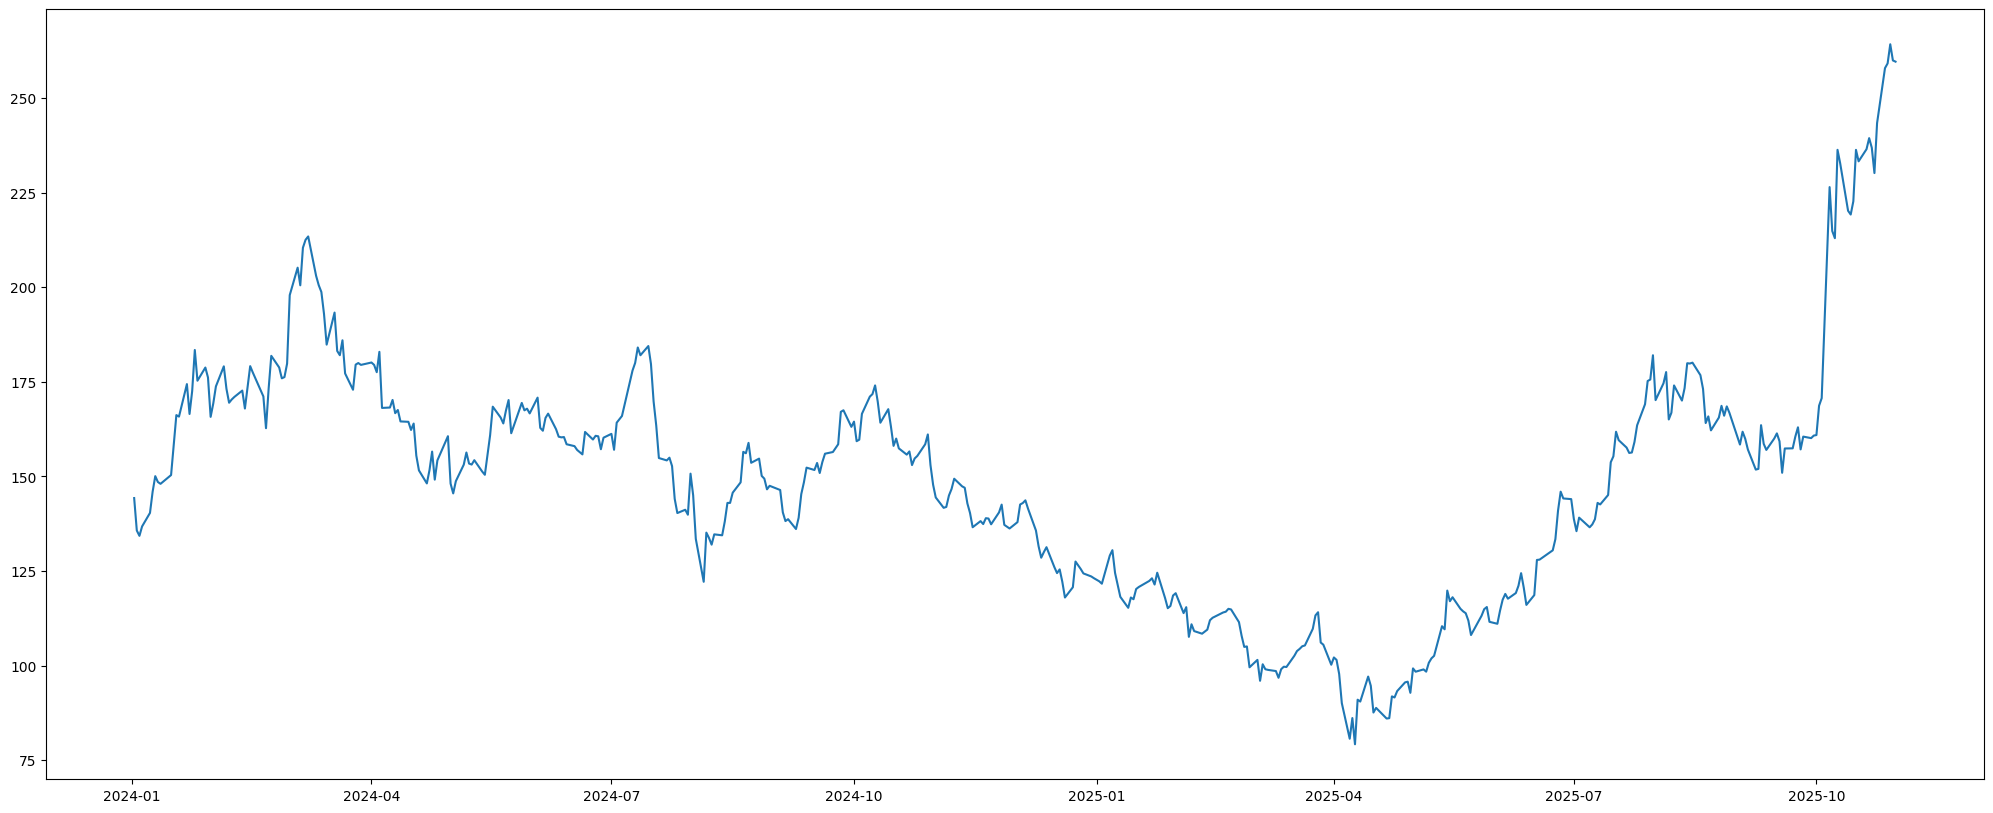

In [9]:
plt.figure(figsize=(25, 10))
plt.plot(data["Open"])
plt.show()

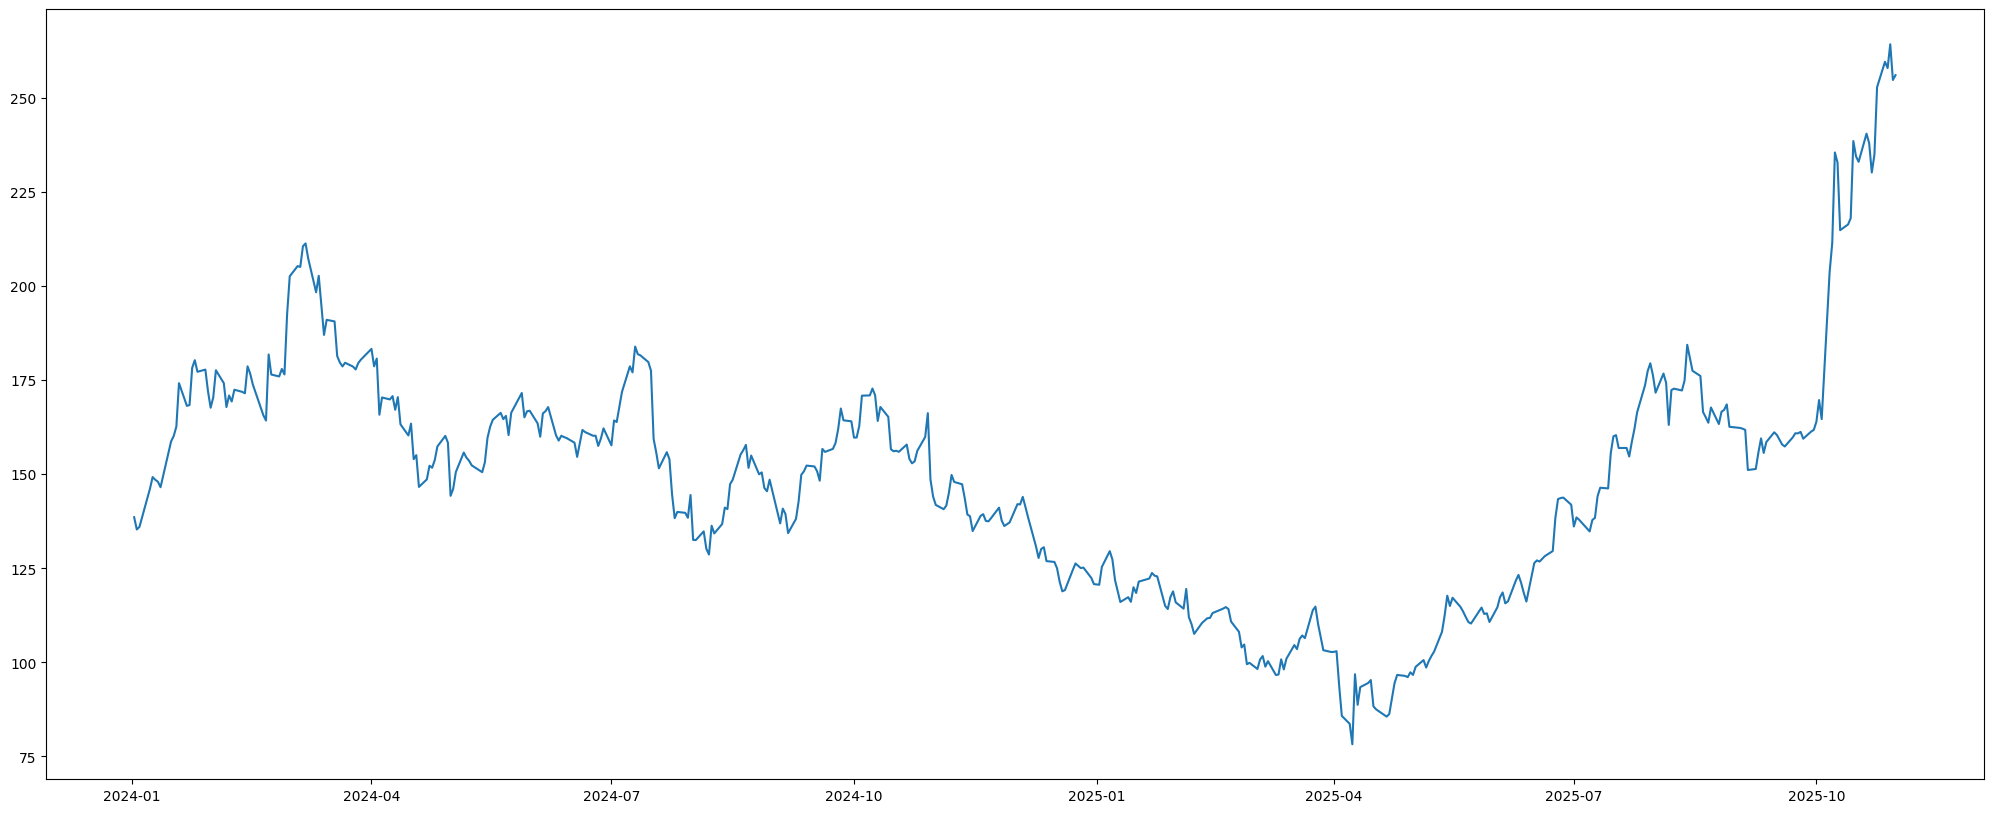

In [10]:
plt.figure(figsize=(25, 10))
plt.plot(data["Close"])
plt.show()

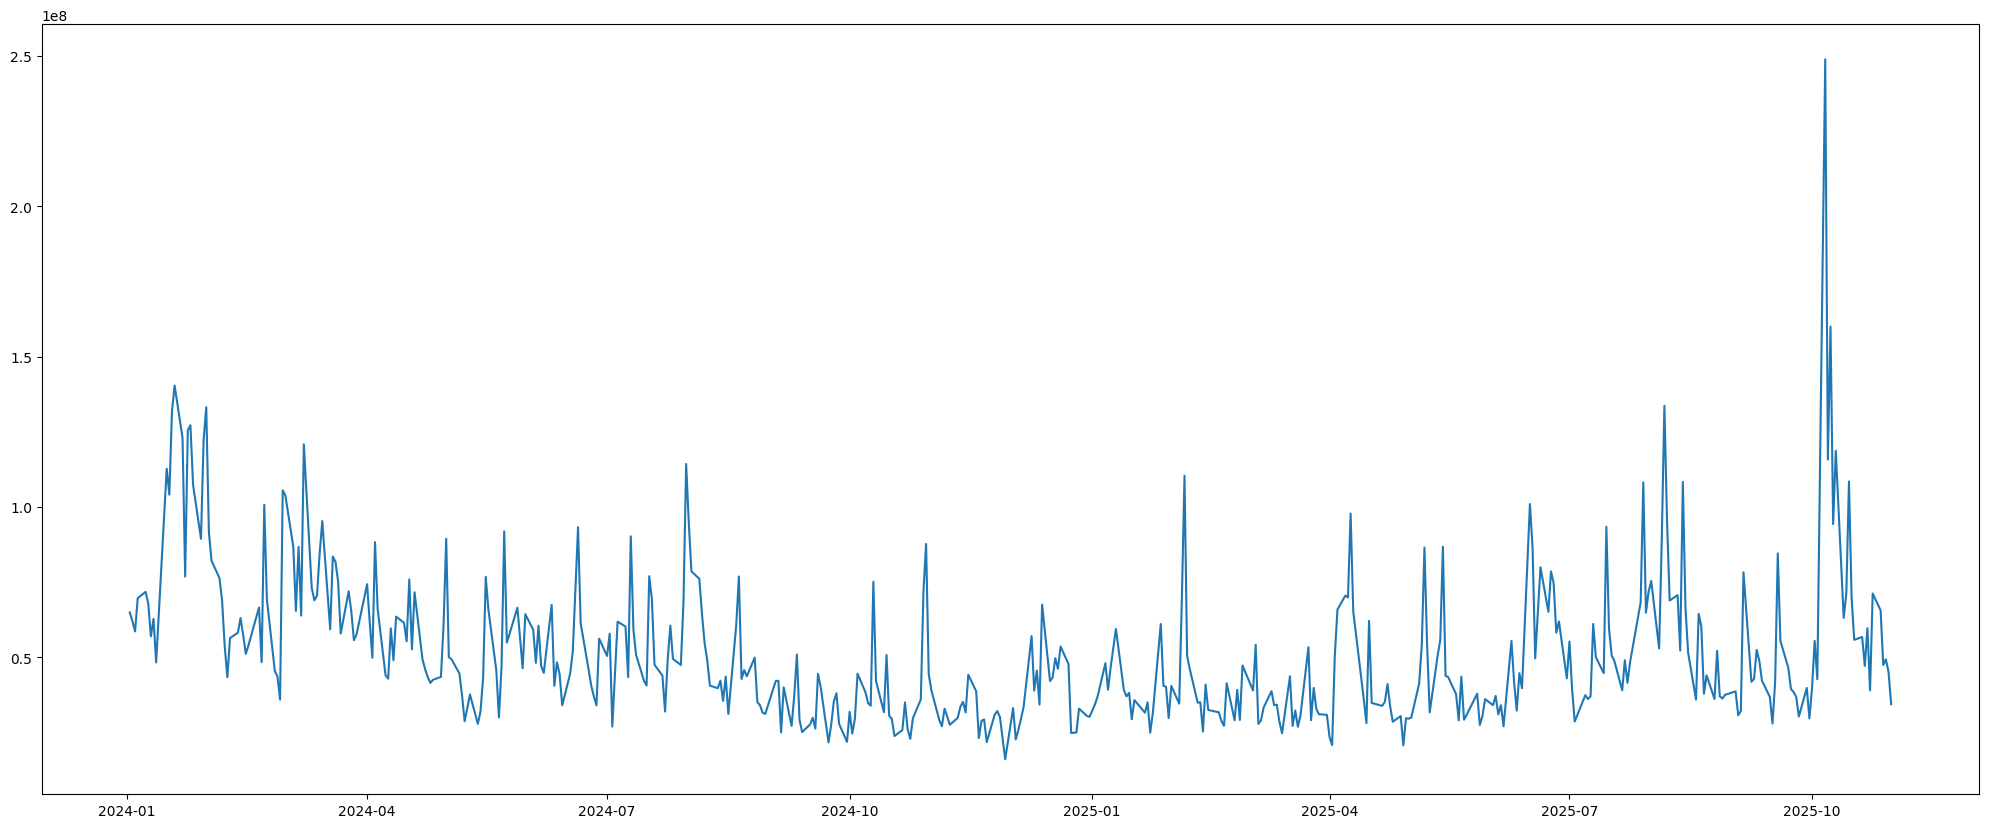

In [11]:
plt.figure(figsize=(25, 10))
plt.plot(data["Volume"])
plt.show()

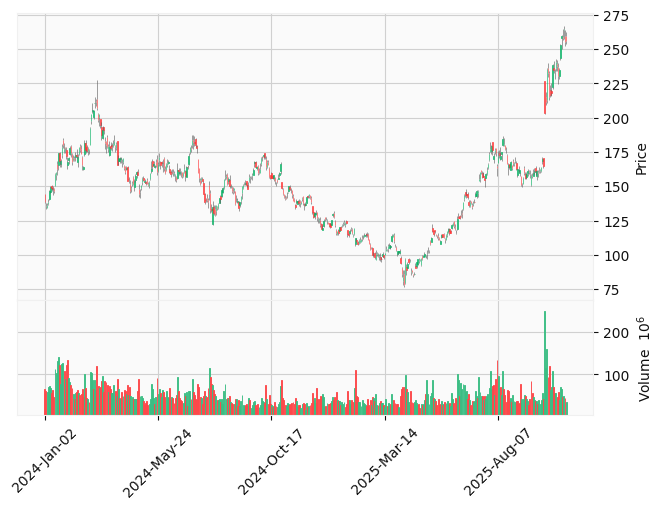

In [12]:
mpf.plot(data, type="candle", style="yahoo", volume=("Volume" in data.columns))

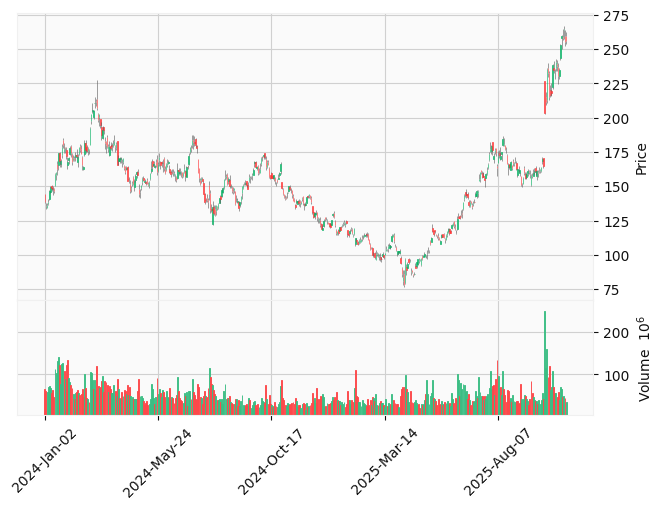

In [13]:
mpf.plot(data, type="candle", style="yahoo", volume=True)

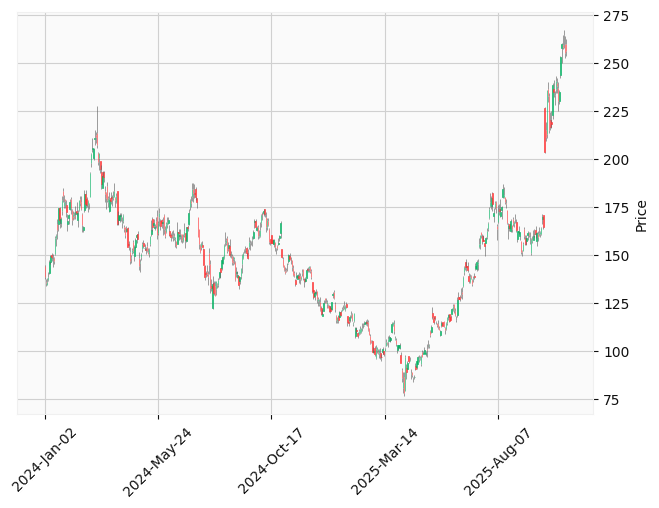

In [14]:
mpf.plot(data, type="candle", style="yahoo", volume=False)

# Save the Cleaned Data

In [15]:
# Save the results as a CSV file for further analysis and reporting
output_path = './data/lab_stockprice_cleaned.csv'
# Ensure the data directory exists
if not os.path.exists('./data'):
    os.makedirs('./data')
# Save the CSV file regardless of environment (Google Colab or local)
data.to_csv(output_path, index=True)
print(f"\n✅ Results saved to {output_path}")


✅ Results saved to ./data/lab_stockprice_cleaned.csv


# Baseline

## Forecast Stock Prices

In [16]:
# If data is already a Series, it uses it directly.
# If data is a DataFrame, it selects the Close column and converts it to float64.
ts = data if isinstance(data, pd.Series) else data["Close"].astype('float64')

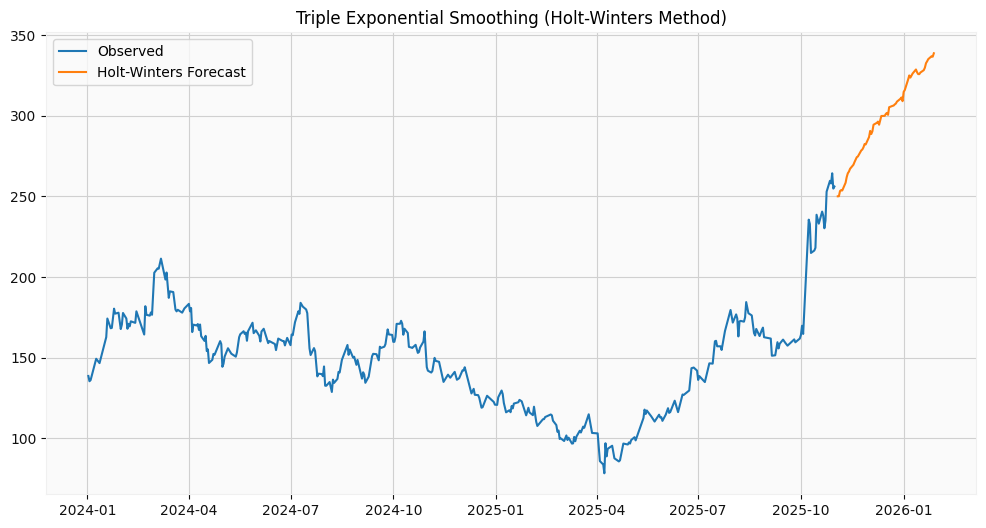

In [17]:
model_hw = ExponentialSmoothing(ts, seasonal_periods=63, trend='add', seasonal='add', initialization_method="estimated").fit()
predictions_hw = model_hw.forecast(63)

future_index = pd.date_range(
    start=ts.index[-1] + pd.offsets.BDay(1),
    periods=63,  # 63 business days ≈ 3 months
    freq='B'
)
predictions_hw = pd.Series(predictions_hw.values, index=future_index)

plt.figure(figsize=(12, 6))
plt.plot(ts, label='Observed')
plt.plot(predictions_hw, label='Holt-Winters Forecast')
plt.title('Triple Exponential Smoothing (Holt-Winters Method)')
plt.legend()
plt.show()

In [18]:
predictions_table = pd.DataFrame(predictions_hw)
predictions_table.columns = ['HW_Forecast']
display(predictions_table)

,HW_Forecast
2025-11-03,250.055199
2025-11-04,250.083556
2025-11-05,253.317873
2025-11-06,253.880224
2025-11-07,253.652024
...,...
2026-01-22,333.810485
2026-01-23,335.135086
2026-01-26,336.970451
2026-01-27,336.654010


## Save Forecasted Data

In [19]:
# Save the results as a CSV file for further analysis and reporting
output_path = './data/forecast_basic.csv'
# Ensure the data directory exists
if not os.path.exists('./data'):
    os.makedirs('./data')
# Save the CSV file regardless of environment (Google Colab or local)
predictions_table.to_csv(output_path, index=True)
print(f"\n✅ Results saved to {output_path}")


✅ Results saved to ./data/forecast_basic.csv


# Intermediate Level

## Compare Multiple Forecasting Methods

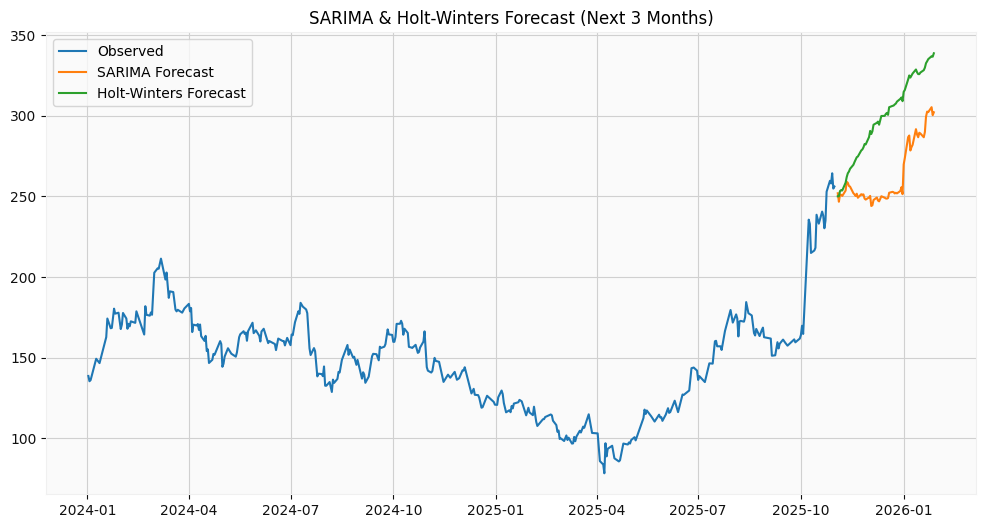

In [20]:
model_sarima = SARIMAX(ts, order=(1, 1, 1), seasonal_order=(1, 1, 1, 63)).fit()
predictions_sarima = model_sarima.forecast(steps=63)

future_index = pd.date_range(
    start=ts.index[-1] + pd.offsets.BDay(1),
    periods=63,
    freq='B'
)
predictions_sarima = pd.Series(predictions_sarima.values, index=future_index)

plt.figure(figsize=(12, 6))
plt.plot(ts, label='Observed')
plt.plot(predictions_sarima, label='SARIMA Forecast')
plt.plot(predictions_hw, label='Holt-Winters Forecast')
plt.title('SARIMA & Holt-Winters Forecast (Next 3 Months)')
plt.legend()
plt.show()


In [21]:
predictions_table['SARIMA_Forecast'] = predictions_sarima
display(predictions_table)

,HW_Forecast,SARIMA_Forecast
2025-11-03,250.055199,251.945313
2025-11-04,250.083556,246.687096
2025-11-05,253.317873,251.128820
2025-11-06,253.880224,250.988292
2025-11-07,253.652024,250.253721
...,...,...
2026-01-22,333.810485,302.591175
2026-01-23,335.135086,302.264777
2026-01-26,336.970451,305.344140
2026-01-27,336.654010,300.377084


## Save Forecasted Data

In [22]:
# Save the results as a CSV file for further analysis and reporting
output_path = './data/forecast_intermediate.csv'
# Ensure the data directory exists
if not os.path.exists('./data'):
    os.makedirs('./data')
# Save the CSV file regardless of environment (Google Colab or local)
predictions_table.to_csv(output_path, index=True)
print(f"\n✅ Results saved to {output_path}")


✅ Results saved to ./data/forecast_intermediate.csv


# Advanced Level

## Baseline LSTM

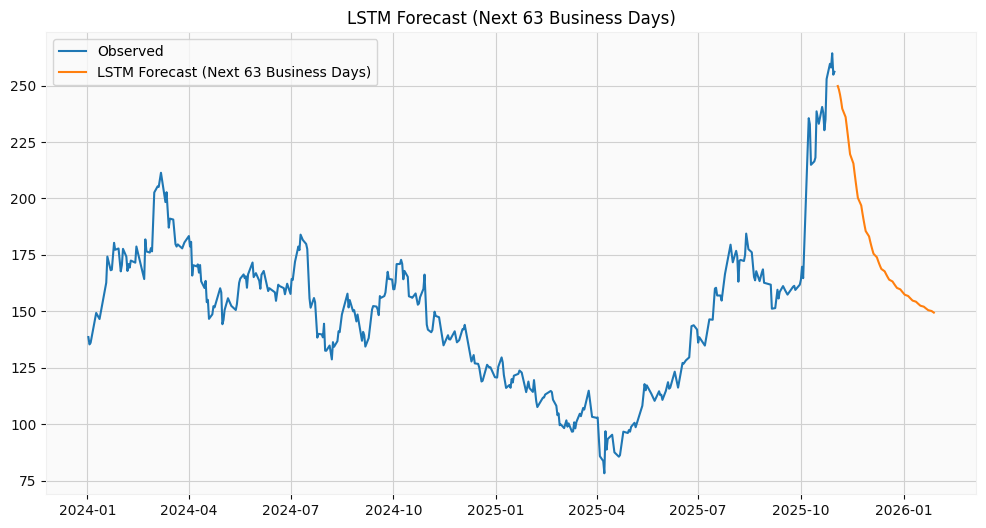

In [23]:
# --- Baseline LSTM using ts ---
window_size = 63

# Scale the data
scaler = MinMaxScaler()
scaled_ts = scaler.fit_transform(ts.values.reshape(-1, 1))

# Create sequences
def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size, 0])
        y.append(data[i+window_size, 0])
    return np.array(X), np.array(y)

X, y = create_sequences(scaled_ts, window_size)
X = X.reshape((X.shape[0], window_size, 1))

# Build and train LSTM model
model = Sequential([
    LSTM(50, activation='tanh', input_shape=(window_size, 1)),
    Dense(1)
])
model.compile(optimizer='adam', loss='mse')
model.fit(X, y, epochs=30, batch_size=16, validation_split=0.1, verbose=0)

# Forecast next 63 business days
last_sequence = scaled_ts[-window_size:].reshape(1, window_size, 1)
future_preds_scaled = []
for _ in range(63):
    pred = model.predict(last_sequence, verbose=0)
    future_preds_scaled.append(pred[0, 0])
    last_sequence = np.concatenate([last_sequence[:, 1:, :], pred.reshape(1, 1, 1)], axis=1)

future_preds = scaler.inverse_transform(np.array(future_preds_scaled).reshape(-1, 1)).flatten()
future_index = pd.date_range(start=ts.index[-1] + pd.offsets.BDay(1), periods=63, freq='B')

# --- Plot the forecast ---
plt.figure(figsize=(12, 6))
plt.plot(ts, label='Observed')
plt.plot(future_index, future_preds, label='LSTM Forecast (Next 63 Business Days)')
plt.title('LSTM Forecast (Next 63 Business Days)')
plt.legend()
plt.show()

In [24]:
predictions_table['LSTM_Baseline_Forecast'] = pd.Series(future_preds, index=future_index)

In [25]:
display(predictions_table)

,HW_Forecast,SARIMA_Forecast,LSTM_Baseline_Forecast
2025-11-03,250.055199,251.945313,249.814026
2025-11-04,250.083556,246.687096,248.289078
2025-11-05,253.317873,251.128820,246.041428
2025-11-06,253.880224,250.988292,243.160812
2025-11-07,253.652024,250.253721,239.795181
...,...,...,...
2026-01-22,333.810485,302.591175,150.859695
2026-01-23,335.135086,302.264777,150.484116
2026-01-26,336.970451,305.344140,150.118347
2026-01-27,336.654010,300.377084,149.762115


## Hyperparameter Tuning

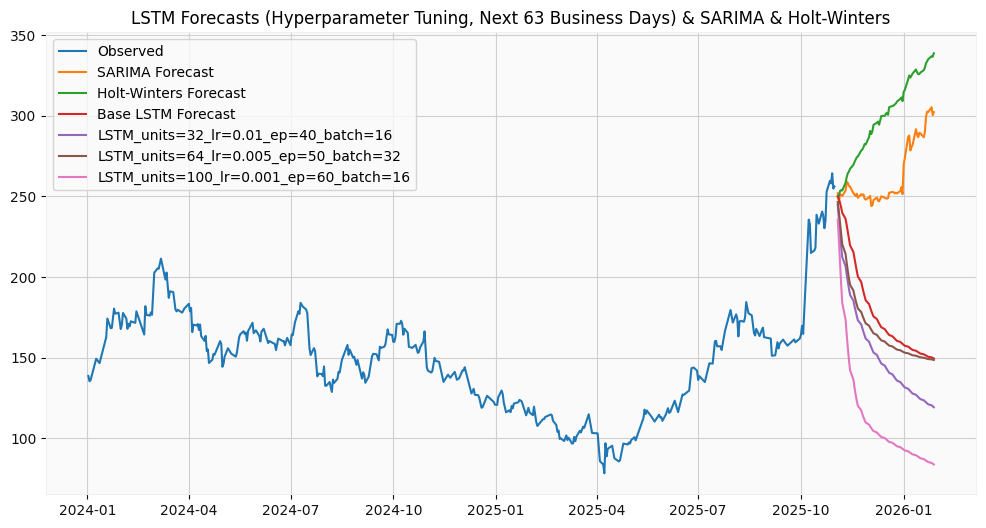

In [26]:
# --- Data Preparation ---
window_size = 63
scaler = MinMaxScaler()
scaled_ts = scaler.fit_transform(ts.values.reshape(-1, 1))

def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size, 0])
        y.append(data[i+window_size, 0])
    return np.array(X), np.array(y)

X, y = create_sequences(scaled_ts, window_size)
X = X.reshape((X.shape[0], window_size, 1))

# --- Hyperparameter Grid ---
hyperparams = [
    {'units': 32, 'lr': 0.01, 'epochs': 40, 'batch': 16},
    {'units': 64, 'lr': 0.005, 'epochs': 50, 'batch': 32},
    {'units': 100, 'lr': 0.001, 'epochs': 60, 'batch': 16}
]

results = {}
for params in hyperparams:
    model = Sequential([
        LSTM(params['units'], activation='tanh', input_shape=(window_size, 1)),
        Dense(1)
    ])
    model.compile(optimizer=Adam(learning_rate=params['lr']), loss='mse')
    model.fit(X, y, epochs=params['epochs'], batch_size=params['batch'], validation_split=0.1, verbose=0)
    # Forecast next 63 business days
    last_seq = scaled_ts[-window_size:].reshape(1, window_size, 1)
    preds_scaled = []
    for _ in range(63):
        pred = model.predict(last_seq, verbose=0)
        preds_scaled.append(pred[0, 0])
        last_seq = np.concatenate([last_seq[:, 1:, :], pred.reshape(1, 1, 1)], axis=1)
    preds = scaler.inverse_transform(np.array(preds_scaled).reshape(-1, 1)).flatten()
    key = f"LSTM_units={params['units']}_lr={params['lr']}_ep={params['epochs']}_batch={params['batch']}"
    results[key] = preds

future_index = pd.date_range(start=ts.index[-1] + pd.offsets.BDay(1), periods=63, freq='B')
results_df = pd.DataFrame(results, index=future_index)

# --- Display Results ---
plt.figure(figsize=(12, 6))
plt.plot(ts, label='Observed')
plt.plot(predictions_sarima, label='SARIMA Forecast')
plt.plot(predictions_hw, label='Holt-Winters Forecast')
plt.plot(future_index, future_preds, label='Base LSTM Forecast')
for col in results_df.columns:
    plt.plot(results_df.index, results_df[col], label=col)
plt.title('LSTM Forecasts (Hyperparameter Tuning, Next 63 Business Days) & SARIMA & Holt-Winters')
plt.legend()
plt.show()

In [27]:
display(results_df)

,LSTM_units=32_lr=0.01_ep=40_batch=16,LSTM_units=64_lr=0.005_ep=50_batch=32,LSTM_units=100_lr=0.001_ep=60_batch=16
2025-11-03,244.863190,246.510986,235.544235
2025-11-04,235.782089,240.448334,223.156052
2025-11-05,226.805954,233.707870,209.148209
2025-11-06,218.970840,226.860092,195.864914
2025-11-07,212.317032,220.290390,183.968842
...,...,...,...
2026-01-22,121.604424,149.265549,85.605034
2026-01-23,120.982765,149.066818,85.128838
2026-01-26,120.369324,148.875061,84.652733
2026-01-27,119.763725,148.689972,84.176605


## Model Comparison

In [28]:
# Get the last 63 actual values as ground truth
actual = ts[-63:].values

# Calculate RMSE for each forecast column
performance_stats = {}
for col in results_df.columns:
    preds = results_df[col].values
    rmse = np.sqrt(np.mean((preds - actual) ** 2))
    performance_stats[col] = {'RMSE': rmse}

for col in ['HW_Forecast', 'SARIMA_Forecast', 'LSTM_Baseline_Forecast']:
    preds = predictions_table[col].values
    rmse = np.sqrt(np.mean((preds - actual) ** 2))
    performance_stats[col] = {'RMSE': rmse}

# Display RMSE results
performance_df = pd.DataFrame(performance_stats).T
display(performance_df)

,RMSE
LSTM_units=32_lr=0.01_ep=40_batch=16,67.016864
LSTM_units=64_lr=0.005_ep=50_batch=32,53.670322
LSTM_units=100_lr=0.001_ep=60_batch=16,94.615244
HW_Forecast,113.994589
SARIMA_Forecast,77.515445
LSTM_Baseline_Forecast,56.637962


In [29]:
# Get the last 63 actual values as ground truth
actual = ts[-63:].values

# Calculate bias for each forecast column
bias_results = {}
for col in results_df.columns:
    preds = results_df[col].values
    bias = np.mean(preds - actual)
    bias_results[col] = bias

for col in ['HW_Forecast', 'SARIMA_Forecast', 'LSTM_Baseline_Forecast']:
    preds = predictions_table[col].values
    bias = np.mean(preds - actual)
    bias_results[col] = bias

# Add bias results to performance stats
for col, bias in bias_results.items():
    performance_stats[col]['Bias'] = bias


In [30]:
# Calculate the trend (slope) for each model's forecast over the 63 days
trend_results = {}
x = np.arange(63)  # Day indices for regression

for col in results_df.columns:
    preds = results_df[col].values
    # Fit a simple linear regression: y = a*x + b
    slope = np.polyfit(x, preds, 1)[0]
    trend_results[col] = slope

for col in ['HW_Forecast', 'SARIMA_Forecast', 'LSTM_Baseline_Forecast']:
    preds = predictions_table[col].values
    slope = np.polyfit(x, preds, 1)[0]
    trend_results[col] = slope

# Add trend results to performance stats
for col, slope in trend_results.items():
    performance_stats[col]['Trend_Slope'] = slope

In [31]:
performance_df = pd.DataFrame(performance_stats).T
display(performance_df)

,RMSE,Bias,Trend_Slope
LSTM_units=32_lr=0.01_ep=40_batch=16,67.016864,-33.637606,-1.596638
LSTM_units=64_lr=0.005_ep=50_batch=32,53.670322,-17.795345,-1.175372
LSTM_units=100_lr=0.001_ep=60_batch=16,94.615244,-74.741644,-1.562730
HW_Forecast,113.994589,111.208396,1.398551
SARIMA_Forecast,77.515445,75.744211,0.837458
LSTM_Baseline_Forecast,56.637962,-8.159805,-1.518177


In [32]:
# Add predictions to the predictions_table
for i in results_df.columns:
    predictions_table[i] = results_df[i]
display(predictions_table)

,HW_Forecast,SARIMA_Forecast,LSTM_Baseline_Forecast,LSTM_units=32_lr=0.01_ep=40_batch=16,LSTM_units=64_lr=0.005_ep=50_batch=32,LSTM_units=100_lr=0.001_ep=60_batch=16
2025-11-03,250.055199,251.945313,249.814026,244.863190,246.510986,235.544235
2025-11-04,250.083556,246.687096,248.289078,235.782089,240.448334,223.156052
2025-11-05,253.317873,251.128820,246.041428,226.805954,233.707870,209.148209
2025-11-06,253.880224,250.988292,243.160812,218.970840,226.860092,195.864914
2025-11-07,253.652024,250.253721,239.795181,212.317032,220.290390,183.968842
...,...,...,...,...,...,...
2026-01-22,333.810485,302.591175,150.859695,121.604424,149.265549,85.605034
2026-01-23,335.135086,302.264777,150.484116,120.982765,149.066818,85.128838
2026-01-26,336.970451,305.344140,150.118347,120.369324,148.875061,84.652733
2026-01-27,336.654010,300.377084,149.762115,119.763725,148.689972,84.176605


## Save Forecasted Data

In [33]:
# Save the results as a CSV file for further analysis and reporting
output_path = './data/forecast_advanced.csv'
# Ensure the data directory exists
if not os.path.exists('./data'):
    os.makedirs('./data')
# Save the CSV file regardless of environment (Google Colab or local)
predictions_table.to_csv(output_path, index=True)
print(f"\n✅ Results saved to {output_path}")


✅ Results saved to ./data/forecast_advanced.csv


In [34]:
# Save to CSV
output_path = './data/forecast_errors_advanced.csv'
performance_df.to_csv(output_path, index=True)

print(f"\n✅ Results saved to {output_path}")


✅ Results saved to ./data/forecast_errors_advanced.csv


## Use of NVIDIA GPU

In [39]:
import torch
import torch_directml

print("PyTorch version:", torch.__version__)
print("DirectML available:", torch_directml.is_available())
print("DirectML device:", torch_directml.device())
print("Number of DirectML devices:", torch_directml.device_count())

PyTorch version: 2.4.1+cpu
DirectML available: True
DirectML device: privateuseone:0
Number of DirectML devices: 2


In [40]:
import torch
import torch.nn as nn
import torch_directml
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt

# Check GPU availability
dml = torch_directml.device()
print(f"DirectML available: {torch_directml.is_available()}")
print(f"Using device: {dml}")

window_size = 12
scaler = MinMaxScaler()
scaled_ts = scaler.fit_transform(ts.values.reshape(-1, 1))

def create_sequences(data, window_size):
    X, y = [], []
    for i in range(len(data) - window_size):
        X.append(data[i:i+window_size, 0])
        y.append(data[i+window_size, 0])
    return np.array(X), np.array(y)

X, y = create_sequences(scaled_ts, window_size)
X = X.reshape((X.shape[0], window_size, 1))

# Convert to PyTorch tensors and move to GPU
X_tensor = torch.FloatTensor(X).to(dml)
y_tensor = torch.FloatTensor(y).to(dml)

# Define LSTM Model
class LSTMModel(nn.Module):
    def __init__(self, hidden_units):
        super(LSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_units, batch_first=True)
        self.fc = nn.Linear(hidden_units, 1)
    
    def forward(self, x):
        lstm_out, _ = self.lstm(x)
        # Take the last time step output
        last_output = lstm_out[:, -1, :]
        prediction = self.fc(last_output)
        return prediction

hyperparams = [
    {'units': 32, 'lr': 0.01, 'epochs': 40, 'batch': 16},
    {'units': 64, 'lr': 0.005, 'epochs': 50, 'batch': 32},
    {'units': 100, 'lr': 0.001, 'epochs': 60, 'batch': 16}
]

results = {}

for params in hyperparams:
    print(f"\nTraining: units={params['units']}, lr={params['lr']}, epochs={params['epochs']}")
    
    # Initialize model and move to GPU
    model = LSTMModel(params['units']).to(dml)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=params['lr'])
    
    # Split data for validation
    split_idx = int(len(X_tensor) * 0.9)
    X_train, X_val = X_tensor[:split_idx], X_tensor[split_idx:]
    y_train, y_val = y_tensor[:split_idx], y_tensor[split_idx:]
    
    # Training loop
    model.train()
    for epoch in range(params['epochs']):
        # Mini-batch training
        for i in range(0, len(X_train), params['batch']):
            batch_X = X_train[i:i+params['batch']]
            batch_y = y_train[i:i+params['batch']]
            
            optimizer.zero_grad()
            outputs = model(batch_X)
            loss = criterion(outputs.squeeze(), batch_y)
            loss.backward()
            optimizer.step()
        
        # Print progress every 10 epochs
        if (epoch + 1) % 10 == 0:
            print(f"Epoch [{epoch+1}/{params['epochs']}], Loss: {loss.item():.6f}")
    
    # Forecast next 63 business days
    model.eval()
    with torch.no_grad():
        # Move to CPU for inference to avoid DirectML issues
        model_cpu = model.cpu()
        last_seq = torch.FloatTensor(scaled_ts[-window_size:].reshape(1, window_size, 1))
        preds_scaled = []
        
        for _ in range(63):
            pred = model_cpu(last_seq)
            pred_value = pred.numpy()[0, 0]
            preds_scaled.append(pred_value)
            
            # Update sequence: remove first element, add prediction
            new_value = torch.FloatTensor([[pred_value]]).unsqueeze(0)
            last_seq = torch.cat([last_seq[:, 1:, :], new_value], dim=1)
        
        preds = scaler.inverse_transform(np.array(preds_scaled).reshape(-1, 1)).flatten()
        key = f"LSTM_units={params['units']}_lr={params['lr']}_ep={params['epochs']}_batch={params['batch']}"
        results[key] = preds

# Create results dataframe
future_index = pd.date_range(start=ts.index[-1] + pd.offsets.BDay(1), periods=63, freq='B')
gpu_results_df = pd.DataFrame(results, index=future_index)
display(gpu_results_df)

# Plot results
plt.figure(figsize=(12, 6))
plt.plot(ts, label='Observed', linewidth=2)
for col in gpu_results_df.columns:
    plt.plot(gpu_results_df.index, gpu_results_df[col], label=col, alpha=0.7)
plt.title('LSTM Forecasts (PyTorch + DirectML GPU, Next 63 Business Days)')
plt.xlabel('Date')
plt.ylabel('Value')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

DirectML available: True
Using device: privateuseone:0

Training: units=32, lr=0.01, epochs=40


NotImplementedError: Could not run 'aten::_thnn_fused_lstm_cell' with arguments from the 'CPU' backend. This could be because the operator doesn't exist for this backend, or was omitted during the selective/custom build process (if using custom build). If you are a Facebook employee using PyTorch on mobile, please visit https://fburl.com/ptmfixes for possible resolutions. 'aten::_thnn_fused_lstm_cell' is only available for these backends: [PrivateUse1, Meta, BackendSelect, Python, FuncTorchDynamicLayerBackMode, Functionalize, Named, Conjugate, Negative, ZeroTensor, ADInplaceOrView, AutogradOther, AutogradCPU, AutogradCUDA, AutogradHIP, AutogradXLA, AutogradMPS, AutogradIPU, AutogradXPU, AutogradHPU, AutogradVE, AutogradLazy, AutogradMTIA, AutogradPrivateUse1, AutogradPrivateUse2, AutogradPrivateUse3, AutogradMeta, AutogradNestedTensor, Tracer, AutocastCPU, AutocastXPU, AutocastCUDA, FuncTorchBatched, BatchedNestedTensor, FuncTorchVmapMode, Batched, VmapMode, FuncTorchGradWrapper, Pytho

In [41]:
# Get the last 63 actual values as ground truth
actual = ts[-63:].values

# Calculate RMSE for GPU forecast column
rmse_results = {}
for col in gpu_results_df.columns:
    preds = gpu_results_df[col].values
    rmse = np.sqrt(np.mean((preds - actual) ** 2))
    rmse_results[col] = rmse

# Display RMSE results
for key, value in rmse_results.items():
    print(f"{key}: GPU RMSE = {value:.4f}")

NameError: name 'gpu_results_df' is not defined

### Impact of Using A GPU when Training
 